# CSCN8000 – Lab 3: Supervised Learning (Logistic and Linear Regression)

**Name:** Davisen Veerasamy
**Student ID:** 8899642
**Section:** 1

This lab has two parts:

| Part | Problem | Type | Algorithm | Dataset |
|---|---|---|---|---|
| **A** | Detect whether a credit card transaction is fraudulent | Binary classification | Logistic Regression | [Credit Card Fraud Detection (Kaggle)](https://www.kaggle.com/datasets/mlg-ulb/creditcard) |
| **B** | Predict a person's medical insurance cost | Regression | Linear Regression | [Medical Cost Personal Dataset (Kaggle)](https://www.kaggle.com/datasets/mirichoi0218/insurance) |

Each part follows the same steps: **load → preprocess → explore (EDA) → split 70/30 → train → evaluate → conclude**.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay, average_precision_score,
    r2_score, mean_absolute_error, mean_squared_error,
)

RANDOM_STATE = 42          # fixed seed so results are reproducible
TEST_SIZE = 0.3            # 70% train / 30% test, as required

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

---
# Part A – Credit Card Fraud Detection (Logistic Regression)

**Problem statement:** Build a machine-learning model that detects whether a credit card transaction is fraudulent. Use a 70/30 train/test split, train a logistic regression model, and evaluate its accuracy.

**About the data:** The dataset holds transactions made by European cardholders over two days in September 2013. For confidentiality, the original features were transformed with PCA into `V1`–`V28`. Only `Time` (seconds since the first transaction) and `Amount` are untransformed. `Class` is the target: **1 = fraud**, **0 = genuine**.

## A.1 Load the data

In [2]:
cc = pd.read_csv("data/creditcard.csv")
print("Shape:", cc.shape)
cc.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [3]:
cc.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

## A.2 Data preprocessing

### Missing values and duplicates

In [4]:
print("Total missing values:", cc.isnull().sum().sum())
print("Duplicate rows      :", cc.duplicated().sum())

Total missing values: 0
Duplicate rows      : 1081


There are no missing values. There are some exact duplicate rows. A duplicate gives the same transaction extra weight and can end up in both the training and the test sets, which would make the test score look better than it really is. I remove them.

In [5]:
cc = cc.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", cc.shape)

Shape after removing duplicates: (283726, 31)


### Summary statistics

In [6]:
cc[["Time", "Amount", "V1", "V2", "V3", "Class"]].describe()

,Time,Amount,V1,V2,V3,Class
count,"283,726.0000","283,726.0000","283,726.0000","283,726.0000","283,726.0000","283,726.0000"
mean,"94,811.0776",88.4727,0.0059,-0.0041,0.0016,0.0017
std,"47,481.0479",250.3994,1.9480,1.6467,1.5087,0.0408
min,0.0000,0.0000,-56.4075,-72.7157,-48.3256,0.0000
25%,"54,204.7500",5.6000,-0.9160,-0.6003,-0.8897,0.0000
50%,"84,692.5000",22.0000,0.0204,0.0639,0.1800,0.0000
75%,"139,298.0000",77.5100,1.3161,0.8003,1.0270,0.0000
max,"172,792.0000","25,691.1600",2.4549,22.0577,9.3826,1.0000


The PCA features `V1`–`V28` are already centred around 0. `Time` and `Amount` are on very different scales (Time reaches about 172,000 and Amount reaches about 25,000). Logistic regression is trained with gradient-based optimisation and regularisation, so these two columns will be **standardised** (mean 0, std 1). The scaler is fitted **after** the train/test split, on the training data only, so that no information leaks from the test set.

## A.3 Exploratory data analysis

### Target class balance

        count  percent
Class                 
0      283253  99.8330
1         473   0.1670


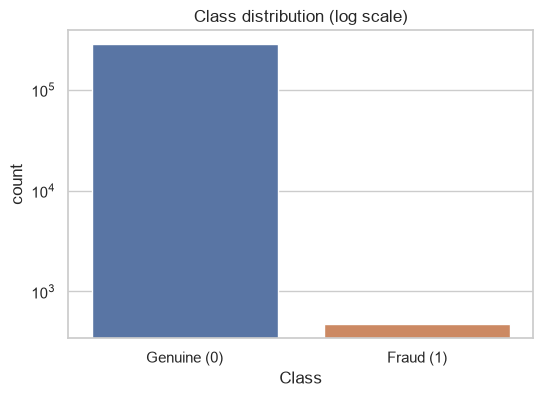

In [7]:
counts = cc["Class"].value_counts()
pct = cc["Class"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": pct.round(3)}))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x="Class", data=cc, ax=ax, hue="Class", palette=["#4C72B0", "#DD8452"], legend=False)
ax.set_yscale("log")
ax.set_title("Class distribution (log scale)")
ax.set_xticks([0, 1], ["Genuine (0)", "Fraud (1)"])
plt.show()

**Finding:** The dataset is **highly imbalanced**: only about **0.17%** of transactions are fraud. A model that always predicts "genuine" would already score about **99.8% accuracy** while catching no fraud at all. For this reason, accuracy alone is not enough to judge the model. I also report precision, recall, F1, ROC-AUC and the confusion matrix.

### Transaction amount and time by class

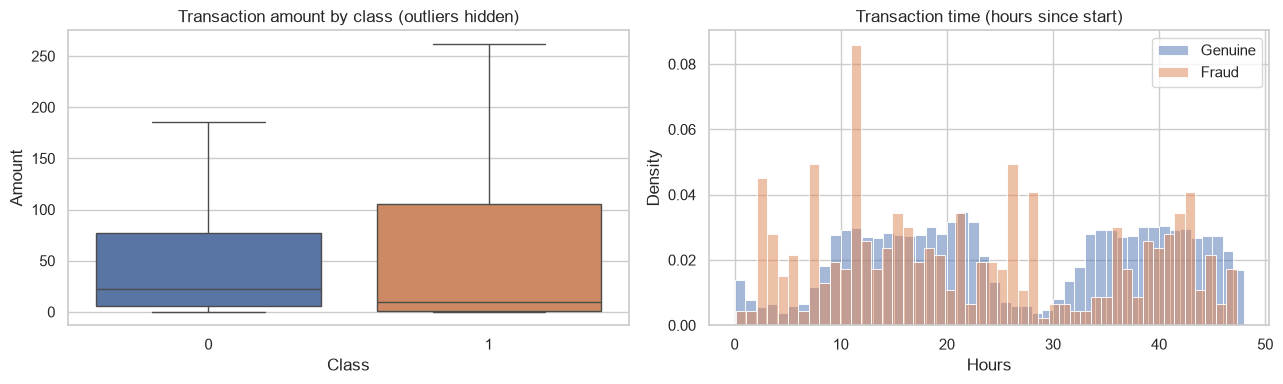

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,"283,253.0000",88.4136,250.3790,0.0000,5.6700,22.0000,77.4600,"25,691.1600"
1,473.0000,123.8719,260.2110,0.0000,1.0000,9.8200,105.8900,"2,125.8700"


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.boxplot(x="Class", y="Amount", data=cc, ax=axes[0], hue="Class",
            palette=["#4C72B0", "#DD8452"], legend=False, showfliers=False)
axes[0].set_title("Transaction amount by class (outliers hidden)")

for cls, colour, label in [(0, "#4C72B0", "Genuine"), (1, "#DD8452", "Fraud")]:
    sns.histplot(cc.loc[cc["Class"] == cls, "Time"] / 3600, bins=48, stat="density",
                 ax=axes[1], color=colour, label=label, alpha=0.5)
axes[1].set_title("Transaction time (hours since start)")
axes[1].set_xlabel("Hours")
axes[1].legend()
plt.tight_layout()
plt.show()

cc.groupby("Class")["Amount"].describe()

**Findings:**
- Fraudulent transactions have a **lower median amount** than genuine ones but a slightly higher mean, so fraud is a mix of many small "test" charges and some larger ones. Fraud amounts never go above about 2,126.
- Genuine transactions follow a clear day/night cycle (two peaks with a dip overnight). Fraud is spread more evenly over the day, so fraud makes up a larger share of the transactions at night.

### Correlation of features with the target

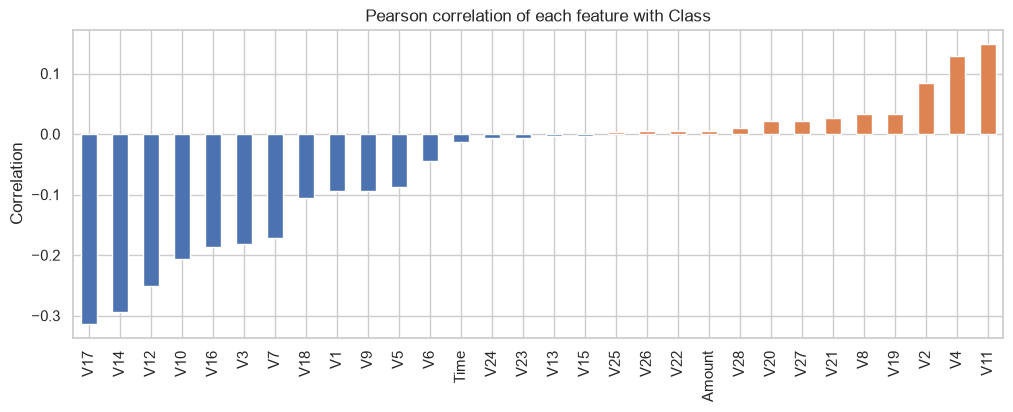

Top 6 features by absolute correlation with Class:
V17   0.3135
V14   0.2934
V12   0.2507
V10   0.2070
V16   0.1872
V3    0.1823
Name: Class, dtype: float64


In [9]:
corr_with_class = cc.corr()["Class"].drop("Class").sort_values()

fig, ax = plt.subplots(figsize=(12, 4))
colors = ["#DD8452" if v > 0 else "#4C72B0" for v in corr_with_class]
corr_with_class.plot(kind="bar", ax=ax, color=colors)
ax.set_title("Pearson correlation of each feature with Class")
ax.set_ylabel("Correlation")
plt.show()

print("Top 6 features by absolute correlation with Class:")
print(corr_with_class.abs().sort_values(ascending=False).head(6))

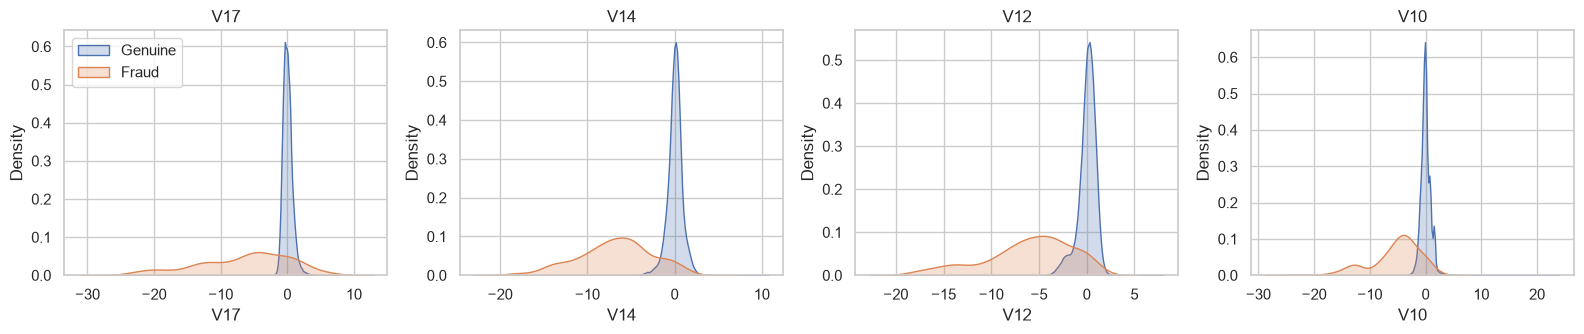

In [10]:
top_feats = ["V17", "V14", "V12", "V10"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, f in zip(axes, top_feats):
    for cls, colour, label in [(0, "#4C72B0", "Genuine"), (1, "#DD8452", "Fraud")]:
        sns.kdeplot(cc.loc[cc["Class"] == cls, f], ax=ax, color=colour, label=label,
                    fill=True, common_norm=False, warn_singular=False)
    ax.set_title(f)
axes[0].legend()
plt.tight_layout()
plt.show()

**Finding:** `V17`, `V14`, `V12` and `V10` have the strongest (negative) correlation with fraud. Their distributions for fraud and genuine transactions barely overlap, so a linear decision boundary such as logistic regression should be able to separate a good part of the fraud cases. The PCA features are uncorrelated with each other by construction, so multicollinearity is not a concern.

## A.4 Train/test split (70/30)

In [11]:
X = cc.drop(columns="Class")
y = cc["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, " fraud rate = {:.4%}".format(y_train.mean()))
print("Test :", X_test.shape,  " fraud rate = {:.4%}".format(y_test.mean()))

Train: (198608, 30)  fraud rate = 0.1667%
Test : (85118, 30)  fraud rate = 0.1668%


I use `stratify=y` so that the very small fraud class is represented in the same proportion in both sets. Without it, the test set could end up with too few fraud cases to evaluate the model properly.

### Feature scaling (fitted on training data only)

In [12]:
scale_cols = ["Time", "Amount"]
scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

X_train[scale_cols].describe().loc[["mean", "std"]]

,Time,Amount
mean,-0.0000,0.0000
std,1.0000,1.0000


## A.5 Build the logistic regression model

In [13]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train, y_train)

y_train_pred = log_reg.predict(X_train)
y_test_pred = log_reg.predict(X_test)
y_test_proba = log_reg.predict_proba(X_test)[:, 1]

## A.6 Evaluate the model

In [14]:
baseline_acc = (y_test == 0).mean()

print(f"Training accuracy : {accuracy_score(y_train, y_train_pred):.4%}")
print(f"Test accuracy     : {accuracy_score(y_test, y_test_pred):.4%}")
print(f"Baseline accuracy (always predict 'genuine'): {baseline_acc:.4%}")
print()
print(f"Precision (fraud) : {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall    (fraud) : {recall_score(y_test, y_test_pred):.4f}")
print(f"F1-score  (fraud) : {f1_score(y_test, y_test_pred):.4f}")
print(f"ROC-AUC           : {roc_auc_score(y_test, y_test_proba):.4f}")
print(f"PR-AUC (avg prec.): {average_precision_score(y_test, y_test_proba):.4f}")

Training accuracy : 99.9240%
Test accuracy     : 99.9107%
Baseline accuracy (always predict 'genuine'): 99.8332%

Precision (fraud) : 0.8438
Recall    (fraud) : 0.5704
F1-score  (fraud) : 0.6807
ROC-AUC           : 0.9650
PR-AUC (avg prec.): 0.7042


In [15]:
print(classification_report(y_test, y_test_pred, target_names=["Genuine", "Fraud"], digits=4))

              precision    recall  f1-score   support

     Genuine     0.9993    0.9998    0.9996     84976
       Fraud     0.8438    0.5704    0.6807       142

    accuracy                         0.9991     85118
   macro avg     0.9215    0.7851    0.8401     85118
weighted avg     0.9990    0.9991    0.9990     85118



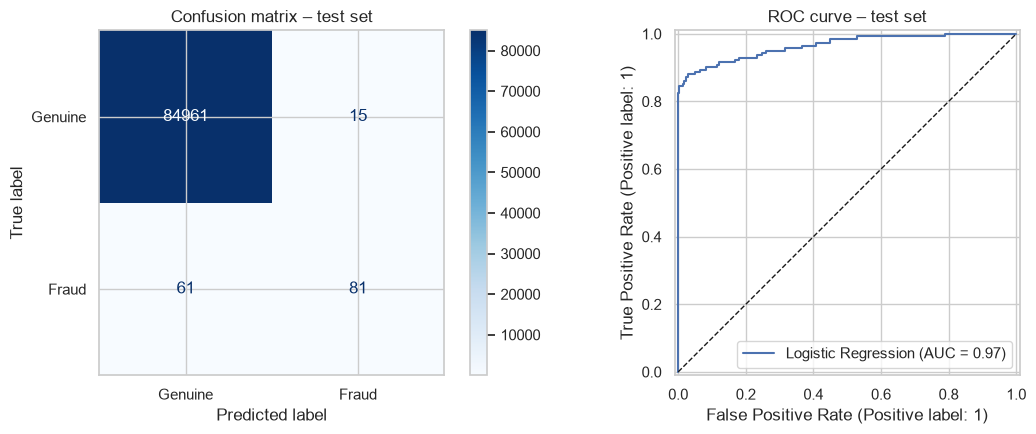

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, display_labels=["Genuine", "Fraud"], cmap="Blues", ax=axes[0], values_format="d"
)
axes[0].set_title("Confusion matrix – test set")
RocCurveDisplay.from_predictions(y_test, y_test_proba, ax=axes[1], name="Logistic Regression")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC curve – test set")
plt.tight_layout()
plt.show()

**Interpretation:**
- The model reaches about **99.91% test accuracy**, and the training accuracy is almost the same, so there is **no overfitting**.
- That figure is only slightly above the **99.83% baseline** of always predicting "genuine". The more useful numbers are for the fraud class:
  - **Precision ≈ 0.84:** when the model flags a transaction as fraud, it is right about 84% of the time.
  - **Recall ≈ 0.57:** the model catches only about 57% of actual fraud cases. The rest (false negatives) go undetected.
- **ROC-AUC ≈ 0.97** shows that the model *ranks* fraud above genuine transactions very well. The default 0.5 probability threshold is simply conservative for such a rare class.

## A.7 Extra: handling the class imbalance

The default model misses many fraud cases. In fraud detection, a missed fraud (false negative) usually costs more than a false alarm. A common fix is `class_weight="balanced"`, which gives each fraud example more weight during training so that the model pays more attention to the rare class. I compare it with the default model below.

In [17]:
log_reg_bal = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
log_reg_bal.fit(X_train, y_train)
y_pred_bal = log_reg_bal.predict(X_test)
y_proba_bal = log_reg_bal.predict_proba(X_test)[:, 1]

def summarise(name, y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "Frauds caught (TP)": tp,
        "Frauds missed (FN)": fn,
        "False alarms (FP)": fp,
    }

comparison = pd.DataFrame([
    summarise("Logistic Regression (default)", y_test, y_test_pred, y_test_proba),
    summarise("Logistic Regression (balanced)", y_test, y_pred_bal, y_proba_bal),
]).set_index("Model")
comparison

,Accuracy,Precision,Recall,F1,ROC-AUC,Frauds caught (TP),Frauds missed (FN),False alarms (FP)
Model,,,,,,,,
Logistic Regression (default),0.9991,0.8438,0.5704,0.6807,0.9650,81,61,15
Logistic Regression (balanced),0.9733,0.0529,0.8873,0.0998,0.9663,126,16,2257


**Finding:** The balanced model raises recall from about **57% to about 89%**, so it catches far more fraud. The cost is many more false alarms (precision drops to about 5%) and a lower accuracy (about 97.3%). Neither model is "best" in every case. The right choice depends on the business cost of a missed fraud compared with the cost of reviewing a false alarm. This trade-off can also be tuned by moving the decision threshold between the two extremes.

## A.8 Part A conclusion

- **Preprocessing:** no missing values. I removed 1,081 duplicate rows and standardised `Time` and `Amount` using a scaler fitted on the training set only.
- **EDA:** the classes are extremely imbalanced (about 0.17% fraud). `V17`, `V14`, `V12` and `V10` are the strongest indicators of fraud.
- **Model:** logistic regression trained on a stratified 70/30 split.
- **Accuracy:** about **99.91%** on the test set (training ≈ 99.92%, so no overfitting). ROC-AUC ≈ 0.97.
- **Key takeaway:** for imbalanced data, accuracy is misleading. Precision, recall and the confusion matrix give the real picture. Class weighting (or threshold tuning) lets the bank trade false alarms for a higher fraud catch rate.

---
# Part B – Insurance Cost Prediction (Linear Regression)

**Problem statement:** Build a predictive system that predicts a person's medical insurance cost (`charges`). Use a 70/30 train/test split, train a linear regression model, and evaluate how accurately it predicts.

**Features:** `age`, `sex`, `bmi` (body-mass index), `children` (number of dependants), `smoker`, `region` (US region). **Target:** `charges` (individual medical costs billed by the insurer).

## B.1 Load the data

In [18]:
ins = pd.read_csv("data/insurance.csv")
print("Shape:", ins.shape)
ins.head()

Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.9000,0,yes,southwest,"16,884.9240"
1,18,male,33.7700,1,no,southeast,"1,725.5523"
2,28,male,33.0000,3,no,southeast,"4,449.4620"
3,33,male,22.7050,0,no,northwest,"21,984.4706"
4,32,male,28.8800,0,no,northwest,"3,866.8552"


In [19]:
ins.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


## B.2 Data preprocessing

In [20]:
print("Missing values per column:")
print(ins.isnull().sum())
print("\nDuplicate rows:", ins.duplicated().sum())
display(ins[ins.duplicated(keep=False)])

Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.5900,0,no,northwest,"1,639.5631"
581,19,male,30.5900,0,no,northwest,"1,639.5631"


In [21]:
ins = ins.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", ins.shape)

Shape after removing duplicates: (1337, 7)


In [22]:
display(ins.describe())
for col in ["sex", "smoker", "region"]:
    print(ins[col].value_counts(), "\n")

,age,bmi,children,charges
count,"1,337.0000","1,337.0000","1,337.0000","1,337.0000"
mean,39.2221,30.6635,1.0957,"13,279.1215"
std,14.0443,6.1005,1.2056,"12,110.3597"
min,18.0000,15.9600,0.0000,"1,121.8739"
25%,27.0000,26.2900,0.0000,"4,746.3440"
50%,39.0000,30.4000,1.0000,"9,386.1613"
75%,51.0000,34.7000,2.0000,"16,657.7175"
max,64.0000,53.1300,5.0000,"63,770.4280"


sex
male      675
female    662
Name: count, dtype: int64 

smoker
no     1063
yes     274
Name: count, dtype: int64 

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64 



There are no missing values, and I removed the one duplicate row. The numeric features have sensible ranges (age 18–64, BMI about 16–53, 0–5 children). The categorical columns are fairly balanced, apart from `smoker`, where about 20% of people smoke.

## B.3 Exploratory data analysis

### Distribution of the target

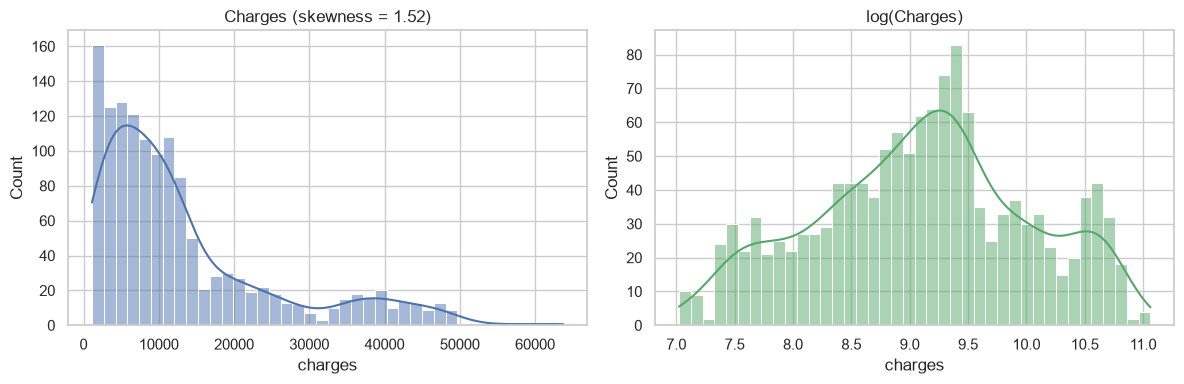

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(ins["charges"], bins=40, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title(f"Charges (skewness = {ins['charges'].skew():.2f})")
sns.histplot(np.log(ins["charges"]), bins=40, kde=True, ax=axes[1], color="#55A868")
axes[1].set_title("log(Charges)")
plt.tight_layout()
plt.show()

**Finding:** `charges` is **right-skewed**. Most people pay under 15,000, but a long tail goes past 60,000. That tail will be the hardest part for a linear model to fit.

### Charges by categorical features

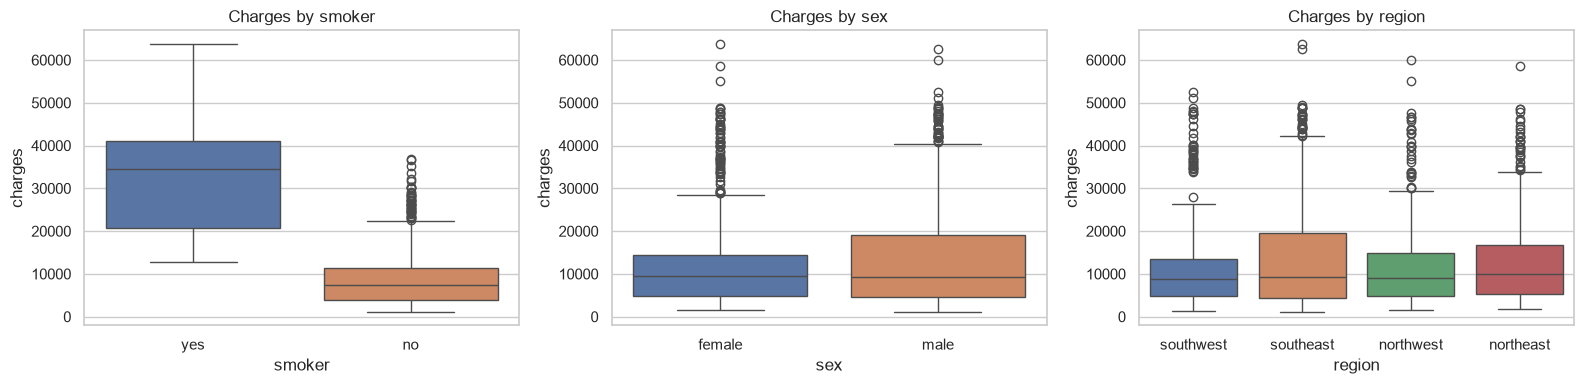

smoker
no     8,440.6600
yes   32,050.2300
Name: charges, dtype: float64


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["smoker", "sex", "region"]):
    sns.boxplot(x=col, y="charges", data=ins, ax=ax, hue=col, legend=False)
    ax.set_title(f"Charges by {col}")
plt.tight_layout()
plt.show()

print(ins.groupby("smoker")["charges"].mean().round(2))

**Finding:** **Smoking** is by far the strongest driver of cost. Smokers pay on average about **32,000**, compared with about **8,400** for non-smokers (roughly 3.8×). Sex and region make only small differences.

### Charges vs. numeric features

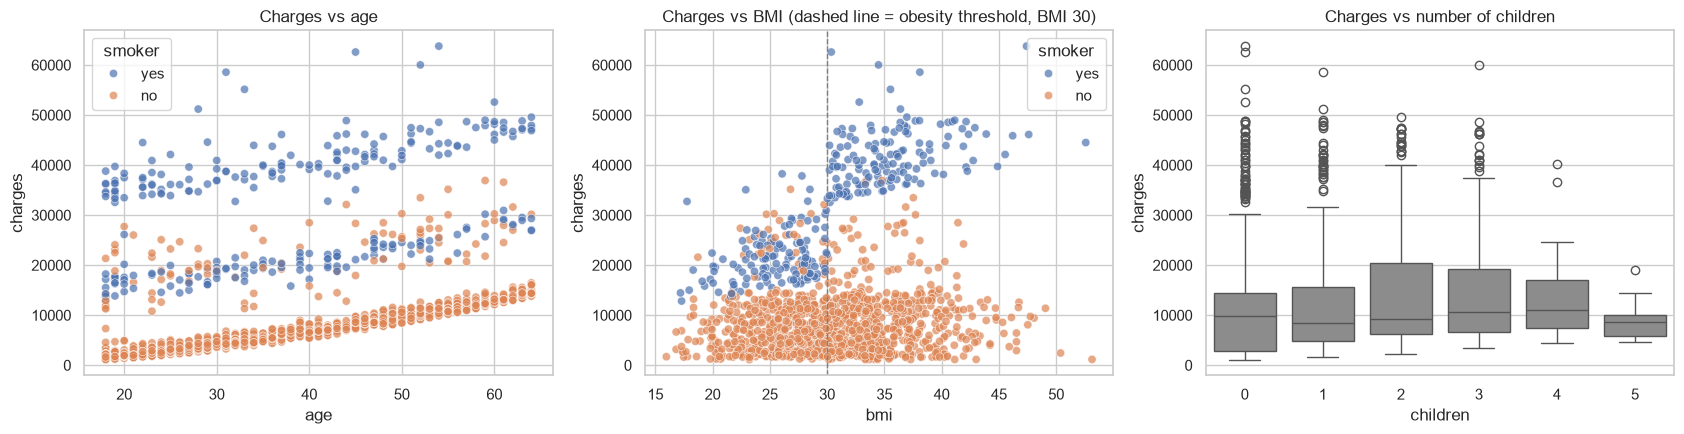

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(x="age", y="charges", hue="smoker", data=ins, ax=axes[0], alpha=0.7)
axes[0].set_title("Charges vs age")
sns.scatterplot(x="bmi", y="charges", hue="smoker", data=ins, ax=axes[1], alpha=0.7)
axes[1].axvline(30, color="grey", ls="--", lw=1)
axes[1].set_title("Charges vs BMI (dashed line = obesity threshold, BMI 30)")
sns.boxplot(x="children", y="charges", data=ins, ax=axes[2], color="#8C8C8C")
axes[2].set_title("Charges vs number of children")
plt.tight_layout()
plt.show()

**Findings:**
- **Age:** charges rise steadily with age. There are three visible "bands": non-smokers at the bottom, smokers at the top, and a mixed band in the middle.
- **BMI:** for non-smokers BMI barely matters, but **smokers with BMI > 30 jump to a much higher cost level**. This is an *interaction* between smoking and BMI, and a plain linear model cannot capture it on its own.
- **Children:** only a weak effect.

### Correlation heatmap (after encoding)

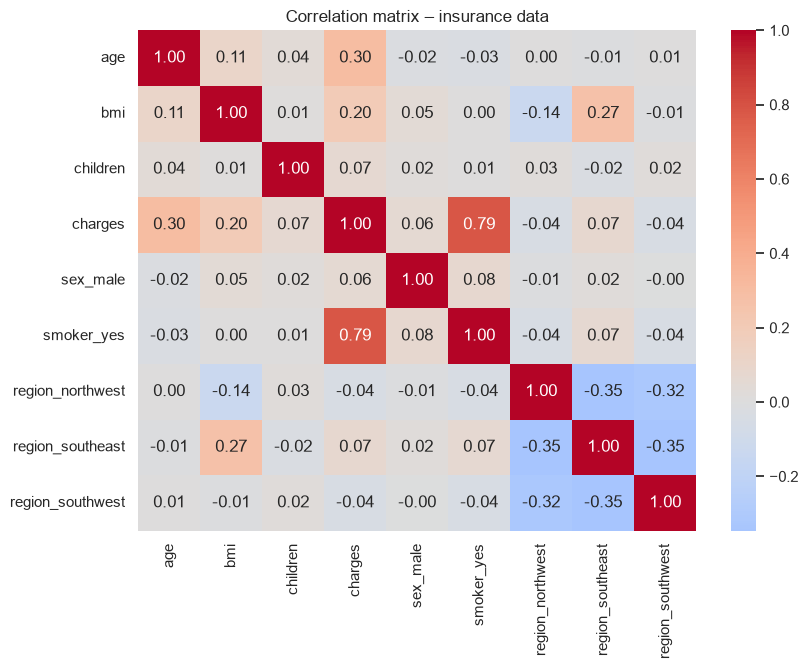

In [26]:
ins_encoded = pd.get_dummies(ins, columns=["sex", "smoker", "region"], drop_first=True, dtype=int)

plt.figure(figsize=(9, 6.5))
sns.heatmap(ins_encoded.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix – insurance data")
plt.show()

**Finding:** `smoker_yes` has the highest correlation with charges (≈ 0.79), followed by `age` (≈ 0.30) and `bmi` (≈ 0.20). The features are only weakly correlated with each other, so multicollinearity is not a problem for linear regression.

## B.4 Encode categorical features and split the data (70/30)

Linear regression needs numeric inputs, so I **one-hot encode** `sex`, `smoker` and `region` with `drop_first=True`. This avoids the "dummy variable trap" (perfect multicollinearity). The dropped categories (`female`, `non-smoker`, `northeast`) become the reference level.

In [27]:
X = ins_encoded.drop(columns="charges")
y = ins_encoded["charges"]
print("Features:", list(X.columns))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Features: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']
Train: (935, 8)  Test: (402, 8)


## B.5 Build the linear regression model

In [28]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

coef = pd.DataFrame({"Coefficient": lin_reg.coef_}, index=X.columns).sort_values("Coefficient", key=abs, ascending=False)
print(f"Intercept: {lin_reg.intercept_:,.2f}")
coef

Intercept: -11,516.78


,Coefficient
smoker_yes,"22,874.4464"
region_southeast,-936.0993
region_southwest,-765.5839
children,522.1554
region_northwest,-465.7466
bmi,328.3831
age,251.2462
sex_male,-111.9072


**Interpreting the coefficients** (all other features held constant):
- Being a **smoker** adds about **$22,900** to the predicted annual charges, by far the largest effect.
- Each extra **year of age** adds about **$251**, each extra **BMI point** adds about **$328**, and each **child** adds about **$522**.
- **Sex** and **region** have small effects compared with the others.

## B.6 Evaluate the model

In [29]:
def regression_metrics(y_true, y_pred):
    return {
        "R²": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    }

y_train_pred = lin_reg.predict(X_train)
y_test_pred = lin_reg.predict(X_test)

metrics = pd.DataFrame({
    "Train": regression_metrics(y_train, y_train_pred),
    "Test": regression_metrics(y_test, y_test_pred),
})
metrics

,Train,Test
R²,0.7363,0.7724
MAE,"4,165.8309","4,181.8160"
RMSE,"5,984.3908","6,240.2059"


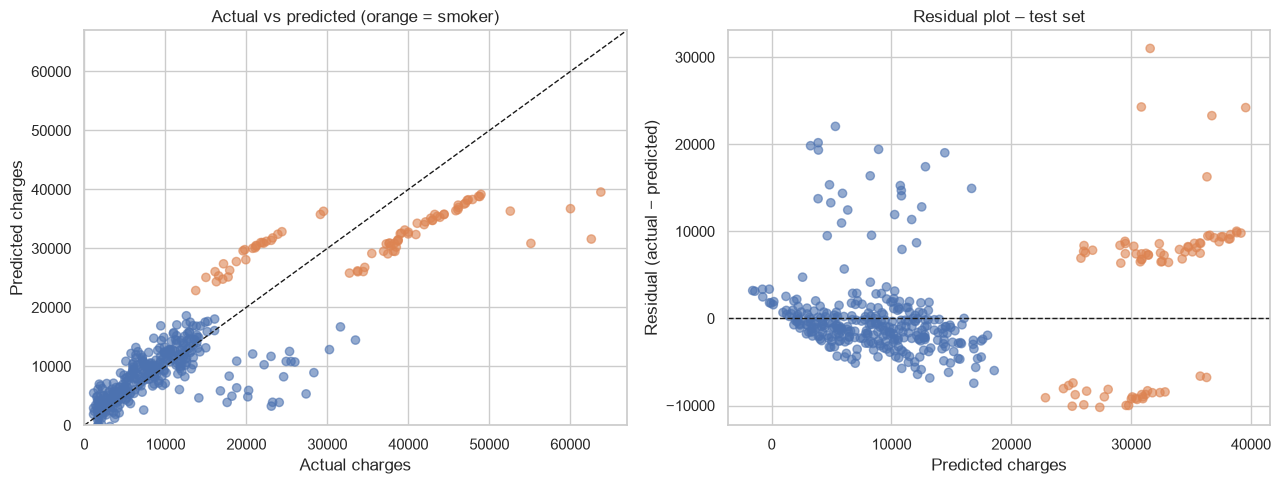

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_test_pred, alpha=0.6, c=X_test["smoker_yes"].map({0: "#4C72B0", 1: "#DD8452"}))
lims = [0, max(y_test.max(), y_test_pred.max()) * 1.05]
axes[0].plot(lims, lims, "k--", lw=1)
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel("Actual charges"); axes[0].set_ylabel("Predicted charges")
axes[0].set_title("Actual vs predicted (orange = smoker)")

residuals = y_test - y_test_pred
axes[1].scatter(y_test_pred, residuals, alpha=0.6, c=X_test["smoker_yes"].map({0: "#4C72B0", 1: "#DD8452"}))
axes[1].axhline(0, color="k", ls="--", lw=1)
axes[1].set_xlabel("Predicted charges"); axes[1].set_ylabel("Residual (actual − predicted)")
axes[1].set_title("Residual plot – test set")
plt.tight_layout()
plt.show()

**Interpretation:**
- **Test R² ≈ 0.77:** the model explains about 77% of the variance in insurance charges on unseen data. Train R² (≈ 0.74) is similar, so the model **does not overfit**.
- **MAE ≈ $4,180:** on average, predictions are off by about $4,200.
- The residual plot is **not random**. The model under-predicts high-cost cases (mostly obese smokers) and over-predicts many low-cost cases. This matches the smoker × BMI interaction and the skewed target seen in the EDA.

## B.7 Extra: improving the linear model with feature engineering

The model can still be linear regression, but with better features. Based on the EDA, I add:
- `obese` = 1 if BMI ≥ 30
- `smoker_obese` = smoker × obese (the interaction seen in the BMI scatter plot)
- `age²` (costs rise faster at older ages)

In [31]:
def add_features(df):
    df = df.copy()
    df["obese"] = (df["bmi"] >= 30).astype(int)
    df["smoker_obese"] = df["smoker_yes"] * df["obese"]
    df["age_sq"] = df["age"] ** 2
    return df

X_train_fe, X_test_fe = add_features(X_train), add_features(X_test)
lin_reg_fe = LinearRegression().fit(X_train_fe, y_train)

pd.DataFrame({
    "Baseline – Test": regression_metrics(y_test, y_test_pred),
    "Engineered – Train": regression_metrics(y_train, lin_reg_fe.predict(X_train_fe)),
    "Engineered – Test": regression_metrics(y_test, lin_reg_fe.predict(X_test_fe)),
})

,Baseline – Test,Engineered – Train,Engineered – Test
R²,0.7724,0.8611,0.8750
MAE,"4,181.8160","2,365.0374","2,515.2677"
RMSE,"6,240.2059","4,342.9218","4,624.0056"


**Finding:** Using the **same linear regression algorithm**, the engineered features raise test **R² from about 0.77 to about 0.875** and cut **MAE from about $4,180 to about $2,515** (a 40% reduction). Train and test scores are still close, so the gain is not overfitting. This confirms the EDA finding that obese smokers form a separate high-cost group.

## B.8 Predictive system

A small function that takes a new person's details and returns the predicted insurance cost, using the baseline linear regression model trained above.

In [32]:
def predict_insurance_cost(age, sex, bmi, children, smoker, region, model=lin_reg):
    person = pd.DataFrame([{"age": age, "sex": sex, "bmi": bmi, "children": children,
                            "smoker": smoker, "region": region}])
    person = pd.get_dummies(person, columns=["sex", "smoker", "region"], dtype=int)
    person = person.reindex(columns=X.columns, fill_value=0)   # same columns/order as training
    return model.predict(person)[0]

examples = [
    dict(age=19, sex="female", bmi=27.9, children=0, smoker="yes", region="southwest"),
    dict(age=45, sex="male",   bmi=24.0, children=2, smoker="no",  region="northeast"),
    dict(age=60, sex="male",   bmi=35.0, children=1, smoker="yes", region="southeast"),
]
for e in examples:
    print(f"{e} -> predicted charges: ${predict_insurance_cost(**e):,.2f}")

{'age': 19, 'sex': 'female', 'bmi': 27.9, 'children': 0, 'smoker': 'yes', 'region': 'southwest'} -> predicted charges: $24,527.65
{'age': 45, 'sex': 'male', 'bmi': 24.0, 'children': 2, 'smoker': 'no', 'region': 'northeast'} -> predicted charges: $8,602.89
{'age': 60, 'sex': 'male', 'bmi': 35.0, 'children': 1, 'smoker': 'yes', 'region': 'southeast'} -> predicted charges: $37,399.99


The first example is the first row of the dataset, whose actual charge is **$16,884.92**. The baseline model predicts about **$24,500**, an over-estimate of about $7,600. This is the pattern seen in the residual plot: the baseline model adds the same smoker premium (about $22,900) to every smoker, while in reality non-obese smokers (this person's BMI is 27.9) pay much less than obese smokers. The engineered model from B.7 handles this case better.

## B.9 Part B conclusion

- **Preprocessing:** no missing values. I removed 1 duplicate row and one-hot encoded `sex`, `smoker` and `region` (drop-first).
- **EDA:** the target is right-skewed. **Smoking** is the dominant cost driver, followed by **age** and **BMI**, and there is a strong smoker × obesity interaction.
- **Model:** multiple linear regression on a 70/30 split.
- **Accuracy:** test **R² ≈ 0.77**, **MAE ≈ $4,180**, **RMSE ≈ $6,240**. Train and test scores are similar, so the model generalises well.
- **Improvement:** feature engineering based on the EDA (obesity flag, smoker × obese interaction, age²) raises test R² to **≈ 0.875** and lowers MAE to **≈ $2,515** with the same linear regression algorithm.

---
# Overall summary

| | Part A – Fraud detection | Part B – Insurance cost |
|---|---|---|
| Task | Classification | Regression |
| Algorithm | Logistic Regression | Linear Regression |
| Split | 70/30 (stratified) | 70/30 |
| Main metric | Accuracy ≈ 99.91% (ROC-AUC ≈ 0.97) | R² ≈ 0.77 (≈ 0.875 with engineered features) |
| Key insight | Accuracy is misleading with a 0.17% fraud rate. Recall and precision matter more. | Smoking dominates cost. An interaction term greatly improves the linear fit. |